In [ ]:
!pip install -q wfdb pandas numpy matplotlib scipy PyWavelets

import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
import pywt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
record_list = wfdb.get_record_list("tpehgdb")
print("Total recordings:", len(record_list))
print("\nFirst 10 recordings:")
print(record_list[:10])
print("\nLast 10 recordings:")
print(record_list[-10:])

Total recordings: 300

First 10 recordings:
['tpehgdb/tpehg1007', 'tpehgdb/tpehg1021', 'tpehgdb/tpehg1022', 'tpehgdb/tpehg1027', 'tpehgdb/tpehg1029', 'tpehgdb/tpehg1031', 'tpehgdb/tpehg1039', 'tpehgdb/tpehg1065', 'tpehgdb/tpehg1070', 'tpehgdb/tpehg1088']

Last 10 recordings:
['tpehgdb/tpehg938', 'tpehgdb/tpehg939', 'tpehgdb/tpehg947', 'tpehgdb/tpehg949', 'tpehgdb/tpehg961', 'tpehgdb/tpehg962', 'tpehgdb/tpehg966', 'tpehgdb/tpehg980', 'tpehgdb/tpehg991', 'tpehgdb/tpehg994']


In [ ]:
test_record_name = record_list[0]
test_record = wfdb.rdrecord(test_record_name, pn_dir="tpehgdb/1.0.1/tpehgdb")
print("Record name:", test_record_name)
print("Sampling frequency:", test_record.fs)
print("Signal shape:", test_record.p_signal.shape)
print("Number of channels:", test_record.n_sig)


Record name: tpehgdb/tpehg1007
Sampling frequency: 20
Signal shape: (35180, 12)
Number of channels: 12


In [ ]:
def extract_features(record_name):
    # 1. Load recording
    record_name = str(record_name).split("/")[-1]
    record = wfdb.rdrecord(record_name, pn_dir="tpehgdb/1.0.1/tpehgdb")
    fs = record.fs

    # 2. Select S1 (0.08–4 Hz)
    signal = record.p_signal[:, 1].astype(float)
    if not np.all(np.isfinite(signal)):
        raise ValueError("Signal contains missing or invalid values.")

    # 3. Remove first and last 180 seconds
    edge_samples = int(180 * fs)
    if len(signal) <= 2 * edge_samples:
        raise ValueError("Recording is too short after cropping.")
    clean_signal = signal[edge_samples : -edge_samples]

    # 4. Time-domain features
    mean_value = np.mean(clean_signal)
    variance = np.var(clean_signal)
    std_value = np.std(clean_signal)
    rms = np.sqrt(np.mean(clean_signal ** 2))
    peak_to_peak = np.max(clean_signal) - np.min(clean_signal)

    features = {
        'record_name': record_name,
        'mean': mean_value,
        'variance': variance,
        'std': std_value,
        'rms': rms,
        'peak_to_peak': peak_to_peak
    }
    return features

In [ ]:
features = extract_features("tpehg1007")

In [ ]:
from scipy.signal import welch, spectrogram
from scipy.integrate import cumulative_trapezoid

print("Additional functions imported successfully!")

Additional functions imported successfully!


In [ ]:
def extract_features(record_name):

    # 1. Load recording
    record_name = str(record_name).split("/")[-1]

    record = wfdb.rdrecord(
        record_name,
        pn_dir="tpehgdb/1.0.1/tpehgdb"
    )

    fs = record.fs

    # 2. Select S1 (0.08–4 Hz)
    signal = record.p_signal[:, 1].astype(float)

    if not np.all(np.isfinite(signal)):
        raise ValueError("Signal contains missing or invalid values.")

    # 3. Remove first and last 180 seconds
    edge_samples = int(180 * fs)

    if len(signal) <= 2 * edge_samples:
        raise ValueError("Recording is too short after cropping.")

    clean_signal = signal[edge_samples:-edge_samples]

    # 4. Time-domain features
    mean_value = np.mean(clean_signal)
    variance = np.var(clean_signal)
    std_value = np.std(clean_signal)

    rms = np.sqrt(np.mean(clean_signal ** 2))

    peak_to_peak = (
        np.max(clean_signal) - np.min(clean_signal)
    )

    zero_crossings = np.sum(
        clean_signal[:-1] * clean_signal[1:] < 0
    )

    zcr = zero_crossings / (len(clean_signal) - 1)

    waveform_length = np.sum(
        np.abs(np.diff(clean_signal))
    )

    # 5. Frequency-domain features using Welch PSD
    frequencies, psd = welch(
        clean_signal,
        fs=fs,
        window="hann",
        nperseg=2048,
        noverlap=1024,
        scaling="density"
    )

    band_mask = (
        (frequencies >= 0.08) &
        (frequencies <= 4.0)
    )

    band_frequencies = frequencies[band_mask]
    band_psd = psd[band_mask]

    total_power = np.trapezoid(
        band_psd,
        band_frequencies
    )

    if total_power <= 0:
        raise ValueError("Invalid or zero band power.")

    mean_frequency = (
        np.trapezoid(
            band_frequencies * band_psd,
            band_frequencies
        ) / total_power
    )

    cumulative_power = cumulative_trapezoid(
        band_psd,
        band_frequencies,
        initial=0
    )

    median_frequency = np.interp(
        total_power / 2,
        cumulative_power,
        band_frequencies
    )

    peak_frequency = band_frequencies[
        np.argmax(band_psd)
    ]

    # 6. Select first five minutes for time-frequency analysis
    tf_duration = 300
    tf_samples = int(tf_duration * fs)

    if len(clean_signal) < tf_samples:
        raise ValueError("Not enough clean signal for 5-minute analysis.")

    segment = clean_signal[:tf_samples]

    # 7. STFT / Spectrogram
    stft_frequencies, stft_times, Sxx = spectrogram(
        segment,
        fs=fs,
        window="hann",
        nperseg=512,
        noverlap=384,
        scaling="density",
        mode="psd"
    )

    stft_mask = (
        (stft_frequencies >= 0.08) &
        (stft_frequencies <= 4.0)
    )

    stft_band = Sxx[stft_mask, :]

    stft_band_frequencies = stft_frequencies[stft_mask]

    mean_spectrogram_power = np.mean(stft_band)

    max_spectrogram_power = np.max(stft_band)

    stft_average_power = np.mean(stft_band, axis=1)

    dominant_stft_frequency = stft_band_frequencies[
        np.argmax(stft_average_power)
    ]

    # 8. Continuous Wavelet Transform (CWT)
    wavelet = "cmor1.5-1.0"

    target_frequencies = np.linspace(0.08, 4.0, 80)

    central_frequency = pywt.central_frequency(wavelet)

    scales = (
        central_frequency * fs / target_frequencies
    )

    coefficients, actual_frequencies = pywt.cwt(
        segment,
        scales,
        wavelet,
        sampling_period=1/fs
    )

    wavelet_power = np.abs(coefficients) ** 2

    mean_wavelet_power = np.mean(wavelet_power)

    max_wavelet_power = np.max(wavelet_power)

    average_wavelet_power = np.mean(
        wavelet_power,
        axis=1
    )

    dominant_wavelet_frequency = actual_frequencies[
        np.argmax(average_wavelet_power)
    ]

    # 9. Collect all features
    features = {

        "Record": record_name,

        "Sampling_Frequency": fs,

        "Original_Samples": len(signal),

        "Clean_Duration_sec": len(clean_signal) / fs,

        "Mean": mean_value,

        "Variance": variance,

        "Standard_Deviation": std_value,

        "RMS": rms,

        "Peak_to_Peak": peak_to_peak,

        "ZCR": zcr,

        "Waveform_Length": waveform_length,

        "Total_Band_Power": total_power,

        "Mean_Frequency": mean_frequency,

        "Median_Frequency": median_frequency,

        "Peak_Frequency": peak_frequency,

        "Mean_Spectrogram_Power": mean_spectrogram_power,

        "Max_Spectrogram_Power": max_spectrogram_power,

        "Dominant_STFT_Frequency": dominant_stft_frequency,

        "Mean_Wavelet_Power": mean_wavelet_power,

        "Max_Wavelet_Power": max_wavelet_power,

        "Dominant_Wavelet_Frequency": dominant_wavelet_frequency
    }

    return features


print("Feature extraction function created successfully!")

Feature extraction function created successfully!


In [ ]:
test_features = extract_features("tpehg1007")

test_feature_df = pd.DataFrame([test_features])

print("Feature extraction successful!")

display(test_feature_df.T)

Feature extraction successful!


,0
Record,tpehg1007
Sampling_Frequency,20
Original_Samples,35180
Clean_Duration_sec,1399.0
Mean,-0.000021
Variance,0.000778
Standard_Deviation,0.027885
RMS,0.027885
Peak_to_Peak,0.269093
ZCR,0.03835


In [ ]:
print("Number of extracted features:", len(test_features))

print("\nFeature names:")
for feature in test_features:
    print(feature)

print("\nMissing values:")
print(test_feature_df.isnull().sum().sum())

Number of extracted features: 21

Feature names:
Record
Sampling_Frequency
Original_Samples
Clean_Duration_sec
Mean
Variance
Standard_Deviation
RMS
Peak_to_Peak
ZCR
Waveform_Length
Total_Band_Power
Mean_Frequency
Median_Frequency
Peak_Frequency
Mean_Spectrogram_Power
Max_Spectrogram_Power
Dominant_STFT_Frequency
Mean_Wavelet_Power
Max_Wavelet_Power
Dominant_Wavelet_Frequency

Missing values:
0


In [ ]:
extract_features("tpehg1007")
extract_features("tpehg1021")
extract_features("tpehg1022")

{'Record': 'tpehg1022',
 'Sampling_Frequency': 20,
 'Original_Samples': 35240,
 'Clean_Duration_sec': 1402.0,
 'Mean': np.float64(-2.3019137882677174e-06),
 'Variance': np.float64(0.0006837387692613274),
 'Standard_Deviation': np.float64(0.026148398980842546),
 'RMS': np.float64(0.026148399082164372),
 'Peak_to_Peak': np.float64(0.3188372625314717),
 'ZCR': np.float64(0.043403830379114806),
 'Waveform_Length': np.float64(57.904783703364615),
 'Total_Band_Power': np.float64(0.0006464452951476448),
 'Mean_Frequency': np.float64(0.2359899392263562),
 'Median_Frequency': np.float64(0.16701287975446225),
 'Peak_Frequency': np.float64(0.107421875),
 'Mean_Spectrogram_Power': np.float64(0.00013526184158563293),
 'Max_Spectrogram_Power': np.float64(0.013062675293403483),
 'Dominant_STFT_Frequency': np.float64(0.2734375),
 'Mean_Wavelet_Power': np.float64(0.0004990316924234054),
 'Max_Wavelet_Power': np.float64(0.04074015039340895),
 'Dominant_Wavelet_Frequency': np.float64(0.12962025316455697)

In [ ]:
import glob, pandas as pd
print("CSV files found:", glob.glob("**/*.csv", recursive=True))

try:
    print("Rows x columns:", master_df.shape)
    print("Missing values:", master_df.isnull().sum().sum())
    display(master_df.head())
except NameError:
    print("master_df does not exist yet in this notebook")

CSV files found: ['sample_data/mnist_test.csv', 'sample_data/mnist_train_small.csv', 'sample_data/california_housing_test.csv', 'sample_data/california_housing_train.csv']
master_df does not exist yet in this notebook


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
from tqdm.auto import tqdm

SAVE_DIR = "/content/drive/MyDrive/uterine-emg-preterm-detection/data"
os.makedirs(SAVE_DIR, exist_ok=True)

test_results, test_errors = [], []
for name in tqdm(record_list[:5]):
    try:
        test_results.append(extract_features(name))
    except Exception as e:
        test_errors.append({"Record": name, "Error": str(e)})

test_df = pd.DataFrame(test_results)
print("Successful:", len(test_results))
print("Failed:", len(test_errors))
print("Shape:", test_df.shape)
print("Missing values:", test_df.isnull().sum().sum())
print(test_errors)

Mounted at /content/drive


  0%|          | 0/5 [00:00<?, ?it/s]

Successful: 5
Failed: 0
Shape: (5, 21)
Missing values: 0
[]


In [ ]:
CHECKPOINT = os.path.join(SAVE_DIR, "tpehg_features_raw.csv")

if os.path.exists(CHECKPOINT):
    done_df = pd.read_csv(CHECKPOINT)
    results = done_df.to_dict("records")
    done = set(done_df["Record"])
    print("Resuming, already done:", len(done))
else:
    results, done = [], set()

errors = []
for i, name in enumerate(tqdm(record_list)):
    if str(name).split("/")[-1] in done:
        continue
    try:
        results.append(extract_features(name))
    except Exception as e:
        errors.append({"Record": name, "Error": str(e)})
    if (i + 1) % 25 == 0:
        pd.DataFrame(results).to_csv(CHECKPOINT, index=False)

master_df = pd.DataFrame(results)
master_df.to_csv(CHECKPOINT, index=False)

print("Successful:", len(master_df))
print("Failed:", len(errors))
print("Shape:", master_df.shape)
print("Missing values:", master_df.isnull().sum().sum())
print(errors[:5])

  0%|          | 0/300 [00:00<?, ?it/s]

Successful: 300
Failed: 0
Shape: (300, 21)
Missing values: 0
[]


In [ ]:
for name in record_list[:3]:
    rec = wfdb.rdrecord(str(name).split("/")[-1], pn_dir="tpehgdb/1.0.1/tpehgdb")
    print("Record:", name)
    for line in rec.comments:
        print("   ", line)
    print("-" * 40)

Record: tpehgdb/tpehg1007
    Comments:
    RecID 1007
    Gestation 35
    Rectime 31.3
    Age 30
    Parity 0
    Abortions 0
    Weight 58
    Hypertension no
    Diabetes no
    Placental_position front
    Bleeding_first_trimester no
    Bleeding_second_trimester no
    Funneling negative
    Smoker no
----------------------------------------
Record: tpehgdb/tpehg1021
    Comments:
    RecID 1021
    Gestation 38.6
    Rectime 22.3
    Age None
    Parity None
    Abortions None
    Weight 63
    Hypertension None
    Diabetes None
    Placental_position end
    Bleeding_first_trimester yes
    Bleeding_second_trimester no
    Funneling negative
    Smoker None
----------------------------------------
Record: tpehgdb/tpehg1022
    Comments:
    RecID 1022
    Gestation 38.6
    Rectime 31
    Age None
    Parity None
    Abortions None
    Weight 70
    Hypertension None
    Diabetes None
    Placental_position end
    Bleeding_first_trimester yes
    Bleeding_second_trimester no

In [ ]:
rows = []
for name in tqdm(record_list):
    clean = str(name).split("/")[-1]
    rec = wfdb.rdrecord(clean, pn_dir="tpehgdb/1.0.1/tpehgdb")
    info = {}
    for line in rec.comments:
        parts = line.split(maxsplit=1)
        if len(parts) == 2:
            info[parts[0]] = parts[1]
    rows.append({
        "Record": clean,
        "Gestation_weeks": float(info["Gestation"]),
        "Rec_time_weeks": float(info["Rectime"]),
    })

labels_df = pd.DataFrame(rows)
labels_df["Label"] = (labels_df["Gestation_weeks"] < 37).map({True: "Preterm", False: "Term"})
labels_df["Target"] = (labels_df["Label"] == "Preterm").astype(int)  # 1 = preterm, 0 = term

print(labels_df["Label"].value_counts())

final_df = master_df.merge(labels_df, on="Record", how="inner")
print("Final shape:", final_df.shape)
print("Missing values:", final_df.isnull().sum().sum())

OUT = os.path.join(SAVE_DIR, "tpehg_features_labeled.csv")
final_df.to_csv(OUT, index=False)
print("Saved:", OUT)
display(final_df[["Record", "Gestation_weeks", "Label", "Target"]].head())

  0%|          | 0/300 [00:00<?, ?it/s]

Label
Term       262
Preterm     38
Name: count, dtype: int64
Final shape: (300, 25)
Missing values: 0
Saved: /content/drive/MyDrive/uterine-emg-preterm-detection/data/tpehg_features_labeled.csv


,Record,Gestation_weeks,Label,Target
0,tpehg1007,35.0,Preterm,1
1,tpehg1021,38.6,Term,0
2,tpehg1022,38.6,Term,0
3,tpehg1027,37.1,Term,0
4,tpehg1029,38.6,Term,0


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/drive/MyDrive/uterine-emg-preterm-detection/data/tpehg_features_labeled.csv")

drop_cols = ["Record", "Gestation_weeks", "Rec_time_weeks", "Label", "Target",
             "Sampling_Frequency", "Original_Samples", "Clean_Duration_sec"]
X = df.drop(columns=drop_cols)
y = df["Target"]

print("Features used:", X.shape[1])
print(list(X.columns))
print("Preterm:", y.sum(), " Term:", (y == 0).sum())

Features used: 17
['Mean', 'Variance', 'Standard_Deviation', 'RMS', 'Peak_to_Peak', 'ZCR', 'Waveform_Length', 'Total_Band_Power', 'Mean_Frequency', 'Median_Frequency', 'Peak_Frequency', 'Mean_Spectrogram_Power', 'Max_Spectrogram_Power', 'Dominant_STFT_Frequency', 'Mean_Wavelet_Power', 'Max_Wavelet_Power', 'Dominant_Wavelet_Frequency']
Preterm: 38  Term: 262


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

scoring = {
    "AUC": "roc_auc",
    "Sensitivity": make_scorer(recall_score, pos_label=1),   # preterm correctly found
    "Specificity": make_scorer(recall_score, pos_label=0),   # term correctly found
    "Balanced_Acc": "balanced_accuracy",
}

models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "SVM (RBF)": SVC(class_weight="balanced", probability=True, random_state=42),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("scale", StandardScaler()), ("model", model)])
    res = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    rows.append({
        "Model": name,
        "AUC": f"{res['test_AUC'].mean():.3f} ± {res['test_AUC'].std():.3f}",
        "Sensitivity": f"{res['test_Sensitivity'].mean():.3f}",
        "Specificity": f"{res['test_Specificity'].mean():.3f}",
        "Balanced_Acc": f"{res['test_Balanced_Acc'].mean():.3f}",
    })

results_df = pd.DataFrame(rows)
display(results_df)
results_df.to_csv("/content/drive/MyDrive/uterine-emg-preterm-detection/data/model_comparison_v1.csv", index=False)

,Model,AUC,Sensitivity,Specificity,Balanced_Acc
0,Logistic Regression,0.447 ± 0.095,0.393,0.539,0.466
1,Random Forest,0.563 ± 0.103,0.000,1.000,0.500
2,SVM (RBF),0.417 ± 0.099,0.332,0.496,0.414


,Feature,Median_Preterm,Median_Term,Single_Feature_AUC,p_value,p_adjusted_Bonferroni
13,Dominant_STFT_Frequency,1.171881e-01,1.171881e-01,0.599,0.0380,0.646
10,Peak_Frequency,1.367195e-01,1.123050e-01,0.571,0.1555,1.000
5,ZCR,5.271551e-02,5.762453e-02,0.433,0.1790,1.000
8,Mean_Frequency,2.955659e-01,3.211883e-01,0.434,0.1910,1.000
16,Dominant_Wavelet_Frequency,1.296203e-01,1.296203e-01,0.538,0.3460,1.000
6,Waveform_Length,5.108770e+01,5.239303e+01,0.460,0.4316,1.000
9,Median_Frequency,1.737776e-01,1.786293e-01,0.468,0.5200,1.000
4,Peak_to_Peak,1.495003e-01,1.532769e-01,0.530,0.5563,1.000
3,RMS,1.413434e-02,1.330709e-02,0.527,0.5897,1.000
2,Standard_Deviation,1.413432e-02,1.330709e-02,0.527,0.5897,1.000


/tmp/ipykernel_1181/2077928864.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([X.loc[y == 0, col], X.loc[y == 1, col]], labels=["Term", "Preterm"])
/tmp/ipykernel_1181/2077928864.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([X.loc[y == 0, col], X.loc[y == 1, col]], labels=["Term", "Preterm"])
/tmp/ipykernel_1181/2077928864.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([X.loc[y == 0, col], X.loc[y == 1, col]], labels=["Term", "Preterm"])
/tmp/ipykernel_1181/2077928864.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_lab

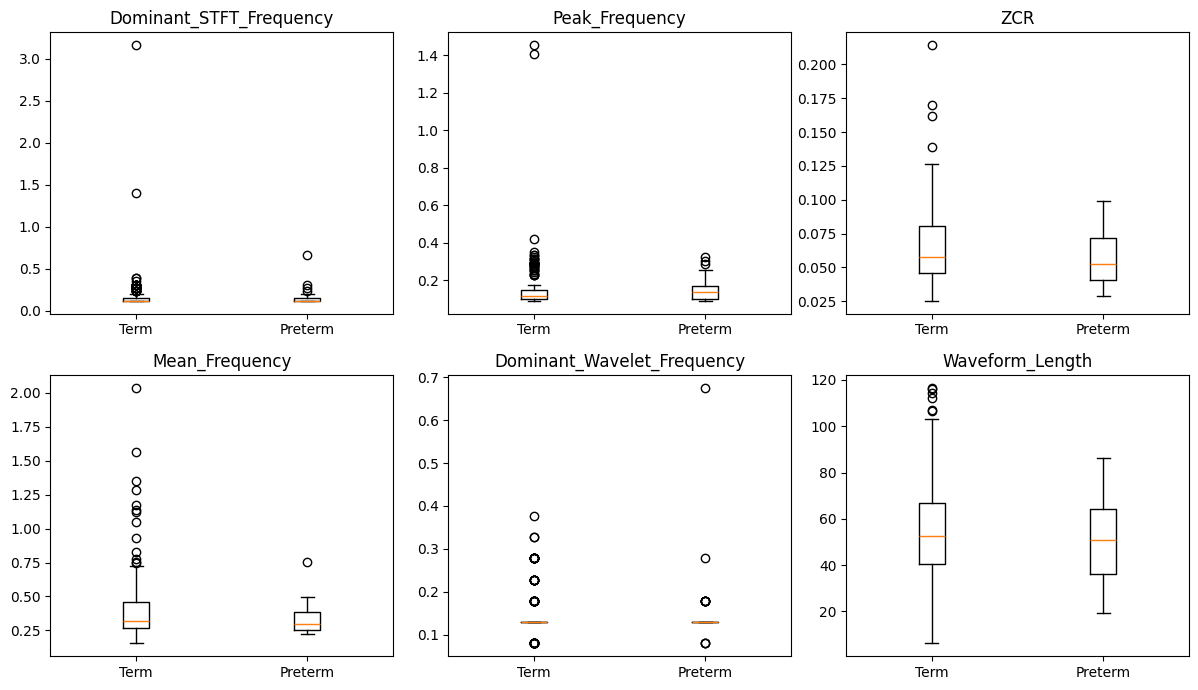

In [ ]:
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

rows = []
for col in X.columns:
    pre = X.loc[y == 1, col]
    term = X.loc[y == 0, col]
    p = mannwhitneyu(pre, term, alternative="two-sided").pvalue
    auc = roc_auc_score(y, X[col])
    rows.append({"Feature": col,
                 "Median_Preterm": pre.median(),
                 "Median_Term": term.median(),
                 "Single_Feature_AUC": round(auc, 3),
                 "p_value": round(p, 4)})

uni = pd.DataFrame(rows).sort_values("p_value")
uni["p_adjusted_Bonferroni"] = (uni["p_value"] * len(uni)).clip(upper=1).round(4)
display(uni)
uni.to_csv("/content/drive/MyDrive/uterine-emg-preterm-detection/data/univariate_tests_v1.csv", index=False)

# Boxplots of the 6 best features
top = uni["Feature"].head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), top):
    ax.boxplot([X.loc[y == 0, col], X.loc[y == 1, col]], labels=["Term", "Preterm"])
    ax.set_title(col)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/uterine-emg-preterm-detection/data/top_features_boxplots_v1.png", dpi=200)
plt.show()

In [ ]:
from scipy.signal import welch
from scipy.integrate import trapezoid, cumulative_trapezoid

# Check the channel order of one record first
rec0 = wfdb.rdrecord("tpehg1007", pn_dir="tpehgdb/1.0.1/tpehgdb")
print("Signal names:", rec0.sig_name)

def extract_features_v2(record_name):
    record_name = str(record_name).split("/")[-1]
    rec = wfdb.rdrecord(record_name, pn_dir="tpehgdb/1.0.1/tpehgdb")
    fs = rec.fs
    edge = int(180 * fs)
    out = {"Record": record_name}

    for ch in range(3):
        x = rec.p_signal[:, ch * 4 + 2].astype(float)   # 0.3-3 Hz filtered version
        if not np.all(np.isfinite(x)):
            raise ValueError("Invalid values in signal")
        x = x[edge:-edge]
        x = x - x.mean()

        f, p = welch(x, fs=fs, window="hann", nperseg=2048, noverlap=1024)
        m = (f >= 0.3) & (f <= 3.0)
        f, p = f[m], p[m]

        total = trapezoid(p, f)
        cum = cumulative_trapezoid(p, f, initial=0)
        pn = p / p.sum()

        tag = f"S{ch+1}"
        out[f"{tag}_RMS"] = np.sqrt(np.mean(x ** 2))
        out[f"{tag}_Peak_Freq"] = f[np.argmax(p)]
        out[f"{tag}_Median_Freq"] = np.interp(total / 2, cum, f)
        out[f"{tag}_Mean_Freq"] = trapezoid(f * p, f) / total
        out[f"{tag}_Spectral_Entropy"] = -(pn * np.log2(pn + 1e-12)).sum() / np.log2(len(pn))
        out[f"{tag}_RelPower_0.3_1Hz"] = trapezoid(p[f <= 1.0], f[f <= 1.0]) / total
        out[f"{tag}_RelPower_2_3Hz"] = trapezoid(p[f >= 2.0], f[f >= 2.0]) / total
    return out

# quick test on one record
display(pd.DataFrame([extract_features_v2("tpehg1007")]).T)

# all 300 recordings
res2, err2 = [], []
for name in tqdm(record_list):
    try:
        res2.append(extract_features_v2(name))
    except Exception as e:
        err2.append({"Record": name, "Error": str(e)})

df2 = pd.DataFrame(res2).merge(
    labels_df[["Record", "Gestation_weeks", "Rec_time_weeks", "Label", "Target"]],
    on="Record")
print("Successful:", len(res2), " Failed:", len(err2))
print("Shape:", df2.shape, " Missing:", df2.isnull().sum().sum())
df2.to_csv("/content/drive/MyDrive/uterine-emg-preterm-detection/data/tpehg_features_v2_labeled.csv", index=False)

Signal names: ['1', '1_DOCFILT-4-0.08-4', '1_DOCFILT-4-0.3-3', '1_DOCFILT-4-0.3-4', '2', '2_DOCFILT-4-0.08-4', '2_DOCFILT-4-0.3-3', '2_DOCFILT-4-0.3-4', '3', '3_DOCFILT-4-0.08-4', '3_DOCFILT-4-0.3-3', '3_DOCFILT-4-0.3-4']


,0
Record,tpehg1007
S1_RMS,0.016478
S1_Peak_Freq,0.322266
S1_Median_Freq,0.374541
S1_Mean_Freq,0.513627
S1_Spectral_Entropy,0.679651
S1_RelPower_0.3_1Hz,0.93433
S1_RelPower_2_3Hz,0.012107
S2_RMS,0.016965
S2_Peak_Freq,0.322266


  0%|          | 0/300 [00:00<?, ?it/s]

Successful: 300  Failed: 0
Shape: (300, 26)  Missing: 0


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

drop2 = ["Record", "Gestation_weeks", "Rec_time_weeks", "Label", "Target"]
X2 = df2.drop(columns=drop2)
y2 = df2["Target"]
print("Features used:", X2.shape[1], "| Preterm:", y2.sum(), "| Term:", (y2 == 0).sum())

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
scoring = {
    "AUC": "roc_auc",
    "Sensitivity": make_scorer(recall_score, pos_label=1),
    "Specificity": make_scorer(recall_score, pos_label=0),
    "Balanced_Acc": "balanced_accuracy",
}
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "SVM (RBF)": SVC(class_weight="balanced", probability=True, random_state=42),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("scale", StandardScaler()), ("model", model)])
    res = cross_validate(pipe, X2, y2, cv=cv, scoring=scoring)
    rows.append({
        "Model": name,
        "AUC": f"{res['test_AUC'].mean():.3f} ± {res['test_AUC'].std():.3f}",
        "Sensitivity": f"{res['test_Sensitivity'].mean():.3f}",
        "Specificity": f"{res['test_Specificity'].mean():.3f}",
        "Balanced_Acc": f"{res['test_Balanced_Acc'].mean():.3f}",
    })

results2 = pd.DataFrame(rows)
display(results2)
results2.to_csv("/content/drive/MyDrive/uterine-emg-preterm-detection/data/model_comparison_v2.csv", index=False)

Features used: 21 | Preterm: 38 | Term: 262


,Model,AUC,Sensitivity,Specificity,Balanced_Acc
0,Logistic Regression,0.510 ± 0.072,0.458,0.547,0.503
1,Random Forest,0.586 ± 0.092,0.000,0.995,0.498
2,SVM (RBF),0.527 ± 0.093,0.528,0.543,0.535


In [ ]:
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

rows = []
for col in X2.columns:
    pre, term = X2.loc[y2 == 1, col], X2.loc[y2 == 0, col]
    rows.append({"Feature": col,
                 "Single_Feature_AUC": round(roc_auc_score(y2, X2[col]), 3),
                 "p_value": round(mannwhitneyu(pre, term).pvalue, 4)})
uni2 = pd.DataFrame(rows).sort_values("p_value")
uni2["p_adjusted_Bonferroni"] = (uni2["p_value"] * len(uni2)).clip(upper=1).round(4)
display(uni2.head(8))
uni2.to_csv("/content/drive/MyDrive/uterine-emg-preterm-detection/data/univariate_tests_v2.csv", index=False)

,Feature,Single_Feature_AUC,p_value,p_adjusted_Bonferroni
19,S3_RelPower_0.3_1Hz,0.649,0.0030,0.0630
17,S3_Mean_Freq,0.363,0.0063,0.1323
16,S3_Median_Freq,0.364,0.0067,0.1407
20,S3_RelPower_2_3Hz,0.366,0.0075,0.1575
18,S3_Spectral_Entropy,0.400,0.0466,0.9786
2,S1_Median_Freq,0.404,0.0564,1.0000
6,S1_RelPower_2_3Hz,0.408,0.0664,1.0000
5,S1_RelPower_0.3_1Hz,0.591,0.0712,1.0000


In [ ]:
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

df2["Rec_group"] = np.where(df2["Rec_time_weeks"] < 27, "Early (<27 wk)", "Late (>=27 wk)")

print("Recordings by recording time and label:")
display(pd.crosstab(df2["Rec_group"], df2["Label"]))

print("\nS3 relative power (0.3-1 Hz), compared within each group:")
for grp, sub in df2.groupby("Rec_group"):
    pre = sub.loc[sub["Target"] == 1, "S3_RelPower_0.3_1Hz"]
    term = sub.loc[sub["Target"] == 0, "S3_RelPower_0.3_1Hz"]
    if len(pre) >= 3 and len(term) >= 3:
        auc = roc_auc_score(sub["Target"], sub["S3_RelPower_0.3_1Hz"])
        p = mannwhitneyu(pre, term).pvalue
        print(f"{grp}: preterm n={len(pre)}, term n={len(term)}, AUC={auc:.3f}, p={p:.4f}")
    else:
        print(f"{grp}: too few preterm cases (n={len(pre)}) to test")

print("\nDoes recording time itself differ between labels?")
print(df2.groupby("Label")["Rec_time_weeks"].describe()[["count", "mean", "min", "max"]])

Recordings by recording time and label:


Label,Preterm,Term
Rec_group,,
Early (<27 wk),19,143
Late (>=27 wk),19,119



S3 relative power (0.3-1 Hz), compared within each group:
Early (<27 wk): preterm n=19, term n=143, AUC=0.707, p=0.0035
Late (>=27 wk): preterm n=19, term n=119, AUC=0.579, p=0.2741

Does recording time itself differ between labels?
         count       mean   min   max
Label                                
Preterm   38.0  27.018421  22.3  31.7
Term     262.0  26.750382  21.6  35.6


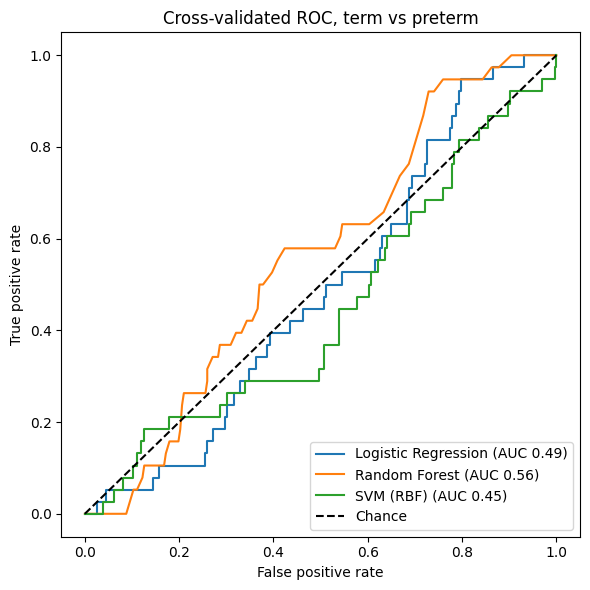

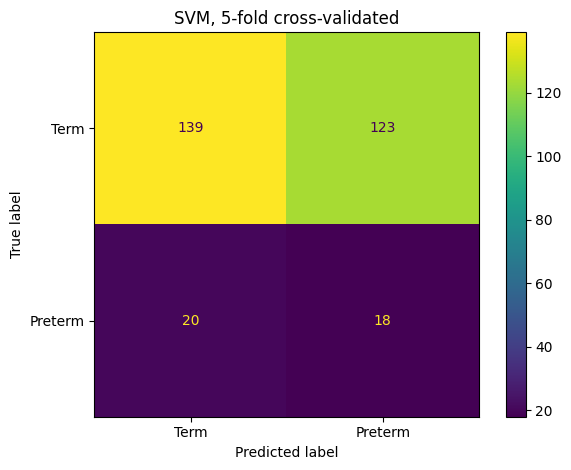

/tmp/ipykernel_1181/102133090.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([sub.loc[sub["Target"] == 0, "S3_RelPower_0.3_1Hz"],
/tmp/ipykernel_1181/102133090.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([sub.loc[sub["Target"] == 0, "S3_RelPower_0.3_1Hz"],


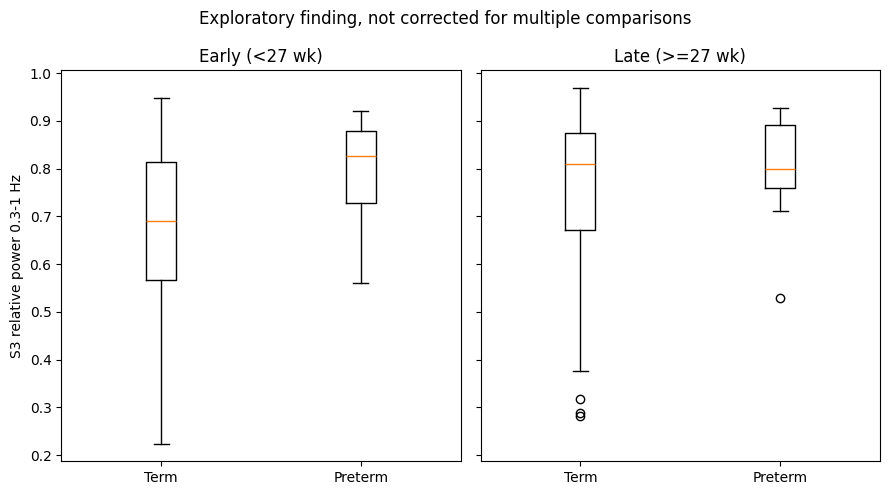

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score, ConfusionMatrixDisplay

FIG = "/content/drive/MyDrive/uterine-emg-preterm-detection/data/"
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Figure 1: cross-validated ROC curves, version 2 features
plt.figure(figsize=(6, 6))
preds = {}
for name, model in models.items():
    pipe = Pipeline([("scale", StandardScaler()), ("model", model)])
    proba = cross_val_predict(pipe, X2, y2, cv=skf, method="predict_proba")[:, 1]
    preds[name] = pipe
    fpr, tpr, _ = roc_curve(y2, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y2, proba):.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Cross-validated ROC, term vs preterm"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG + "fig1_roc_v2.png", dpi=200); plt.show()

# Figure 2: confusion matrix for the SVM
pipe_svm = Pipeline([("scale", StandardScaler()), ("model", models["SVM (RBF)"])])
pred = cross_val_predict(pipe_svm, X2, y2, cv=skf)
ConfusionMatrixDisplay.from_predictions(y2, pred, display_labels=["Term", "Preterm"])
plt.title("SVM, 5-fold cross-validated"); plt.tight_layout()
plt.savefig(FIG + "fig2_confusion_svm.png", dpi=200); plt.show()

# Figure 3: the exploratory S3 feature, by recording time
fig, axes = plt.subplots(1, 2, figsize=(9, 5), sharey=True)
for ax, (grp, sub) in zip(axes, df2.groupby("Rec_group")):
    ax.boxplot([sub.loc[sub["Target"] == 0, "S3_RelPower_0.3_1Hz"],
                sub.loc[sub["Target"] == 1, "S3_RelPower_0.3_1Hz"]],
               labels=["Term", "Preterm"])
    ax.set_title(grp)
axes[0].set_ylabel("S3 relative power 0.3-1 Hz")
plt.suptitle("Exploratory finding, not corrected for multiple comparisons")
plt.tight_layout(); plt.savefig(FIG + "fig3_s3_by_recording_time.png", dpi=200); plt.show()